# Анализ А/В-теста новой фичи

**Цель теста:** проверить, влияет ли новая фича на конверсию.

**Данные** Данные взяты из Kaggle. Ожидаемый результат - рост конверсии.

In [3]:
# 1. Загрузка и первичная разведка данных (Data Profiling)

import pandas as pd

df = pd.read_csv('ab_test_dataset.csv')

print(df.head())
print()
df.info()
print()
print(df.isna().sum())

   user_id    variant country       os  is_converted      assignment_date  \
0   228752  treatment   Italy  Android             0  2026-06-14 12:13:00   
1   120528    control   Spain  Android             0  2026-07-07 18:46:00   
2   103538  treatment   Italy  Android             0  2026-07-03 04:16:00   
3   213462  treatment   Italy      iOS             0  2026-06-10 21:08:00   
4   130506  treatment      UK      iOS             1  2026-06-05 23:13:00   

                 conversion_date  prior_30d_sessions  is_existing_user  
0                            NaN                 2.0               1.0  
1                            NaN                 2.0               1.0  
2                            NaN                 3.0               1.0  
3                            NaN                 3.0               1.0  
4  2026-06-06 13:22:56.108119806                 4.0               1.0  

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 9 columns):

**Вывод:** пропуски в conversion_date, prior_30d_sessions и is_existing_user логически обоснованы. Данные чистые, можно приступать к проверке.

In [4]:
# Sanity Check: проверка баланса групп и наличия дубликатов

print("=== Размеры групп ===")
print(df['variant'].value_counts())

print("\n=== Дубликаты user_id ===")
print(df.duplicated(subset=['user_id']).sum())

print("\n=== Конверсия по группам ===")
print(df.groupby('variant')['is_converted'].mean() * 100)

=== Размеры групп ===
variant
treatment    75000
control      75000
Name: count, dtype: int64

=== Дубликаты user_id ===
0

=== Конверсия по группам ===
variant
control       9.213333
treatment    10.608000
Name: is_converted, dtype: float64


**Вывод:** группы сбалансированы, дубликатов нет, тест валиден.

In [5]:
# Статистический тест (Z-тест для пропорций)
# Использую Z-тест для пропорций, так как конверсия - бинарный признак, а выборка достаточно велика

from statsmodels.stats.proportion import proportions_ztest

conversions = df.groupby('variant')['is_converted'].sum()
nobs = df.groupby('variant')['user_id'].count()
stat, p_value = proportions_ztest(conversions, nobs)

print(f"Z-статистика: {stat:.4f}")
print(f"p-value: {p_value}")

Z-статистика: -9.0385
p-value: 1.5878881974766166e-19


**Вывод:** p-value < 0.05, Z-статистика отрицательная. Фича значимо повышает конверсию.

In [6]:
# Сегментный анализ: проверка влияния ОС на конверсию

print("=== Конверсия по ОС и группам ===")
print(df.groupby(['os', 'variant'])['is_converted'].mean() * 100)

=== Конверсия по ОС и группам ===
os       variant  
Android  control       8.916245
         treatment    10.304906
iOS      control       9.858583
         treatment    11.353925
other    control       8.338638
         treatment     8.430769
Name: is_converted, dtype: float64


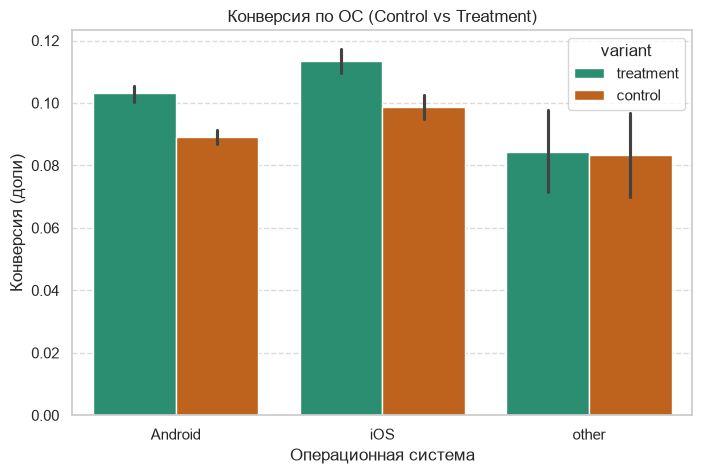

In [7]:
# Визуализация результатов

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted')

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='os', y='is_converted', hue='variant', palette='Dark2')
plt.title('Конверсия по ОС (Control vs Treatment)')
plt.ylabel('Конверсия (доли)')
plt.xlabel('Операционная система')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('conversion_by_os.png', dpi=300, bbox_inches='tight')
plt.show()

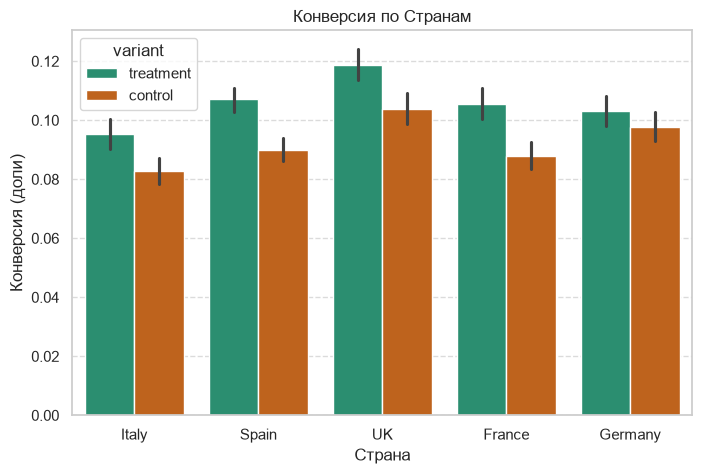

In [22]:
# Визуализация результатов

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='country', y='is_converted', hue='variant', palette='Dark2')
plt.title('Конверсия по Странам')
plt.ylabel('Конверсия (доли)')
plt.xlabel('Страна')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Вывод:** прирост конверсии в Германии меньше, чем в других странах. Проверим, связано ли это с ОС, которой пользуется подавляющее число пользователей.

In [19]:
country_os_counts = pd.crosstab(df['country'], df['os'])
print(country_os_counts)

os       Android    iOS  other
country                       
France     18328   9656    537
Germany    16720   7924    742
Italy      19398   7203    519
Spain      28936  12254    815
UK         14241  12144    583


**Вывод:** низкая конверсия в Германии не связана с ОС. Проверим, не было ли сбоев в работе продукта в Германии, а также, насколько активны были пользователи из Германии.

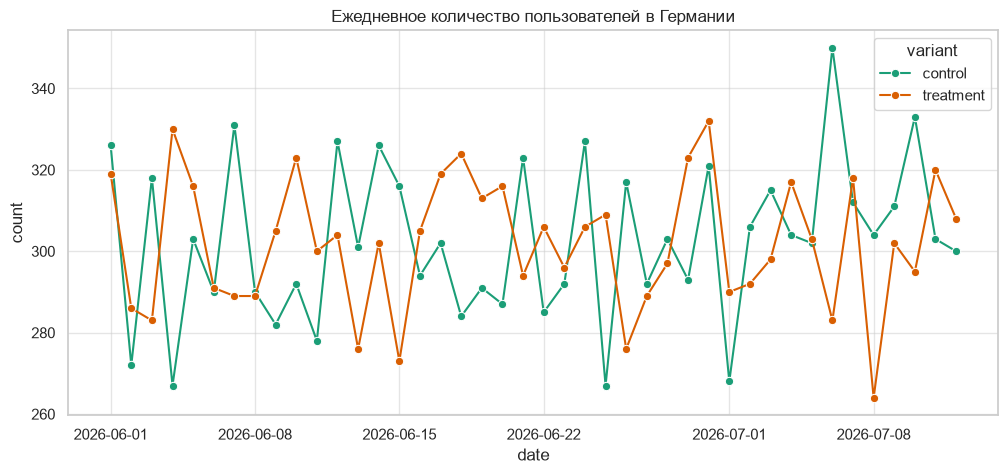

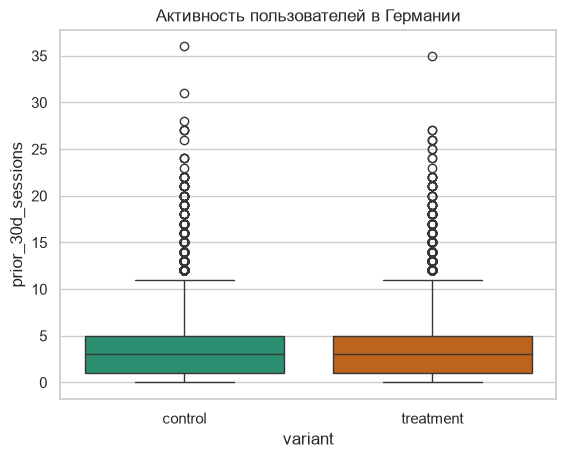

In [20]:
# Для анализа по дням оставляем только дату

df_germany = df[df['country'] == 'Germany'].copy()
df_germany['date'] = pd.to_datetime(df_germany['assignment_date']).dt.date

# Количество ежедневных конверсий

germany_daily = df_germany.groupby(['date', 'variant'])['is_converted'].agg(['count', 'mean']).reset_index()
germany_daily_sorted = germany_daily.sort_values('date')

# Визуализация результатов

plt.figure(figsize=(12, 5))
sns.lineplot(data=germany_daily_sorted, x='date', y='count', hue='variant', palette='Dark2', marker='o')
plt.title('Ежедневное количество пользователей в Германии')
plt.grid(True, alpha=0.5)
plt.show()

sns.boxplot(data=df_germany, x='variant', y='prior_30d_sessions', hue='variant', palette='Dark2')
plt.title('Активность пользователей в Германии')
plt.show()

**Вывод:** график количества пользователей ровный, минимальное значение составляет 264 человека. Технических сбоев не было. Боксплот активности пользователей показал, что группы сбалансированы.

Проверим, было ли нам достаточно данных, чтобы заметить эффект в Германии? 
Проведем Post-hoc анализ мощности (Power Analysis). Сравним размер выборки, который был в Германии, с тем, который необходим для обнаружения эффекта в +1.4 п.п. с мощностью 80% и учетом поправки Бонферрони (α = 0.01).

In [21]:
# p-value для Германии

conv_g = df_germany.groupby('variant')['is_converted'].sum()
nobs_g = df_germany.groupby('variant')['user_id'].count()
stat_g, p_value_g = proportions_ztest(conv_g, nobs_g)

# Требуемый размер выборки

baseline_rate = df[df['variant'] == 'control']['is_converted'].mean()
target_rate = df[df['variant'] == 'treatment']['is_converted'].mean()
effect_size = 2 * np.arcsin(np.sqrt(target_rate)) - 2 * np.arcsin(np.sqrt(baseline_rate))

required_n = zt_ind_solve_power(
    effect_size=abs(effect_size), alpha=0.01, power=0.8, ratio=1.0, alternative='two-sided'
)

# Текущий размер выборки

actual_n_control = len(df_germany[df_germany['variant'] == 'control'])
actual_n_treatment = len(df_germany[df_germany['variant'] == 'treatment'])

print(f"p-value в Германии: {p_value_g:.4f}")
print(f"Требуемый размер выборки на группу (для мощности 80%): {int(required_n)}")
print(f"Фактический размер выборки: {actual_n_control} (Control) и {actual_n_treatment} (Treatment)")

p-value в Германии: 0.1593
Требуемый размер выборки на группу (для мощности 80%): 10709
Фактический размер выборки: 12705 (Control) и 12681 (Treatment)


**Вывод по Германии:** фактический размер выборки в Германии (12 705 человек на группу) превышает минимально необходимый (10 709 человек), требуемый для обнаружения среднего эффекта (+1.39 п.п.) с мощностью 80%. Следовательно, выборки было достаточно. Так как статистически значимого эффекта (p-value = 0.1593) не обнаружено — фича в Германии действительно не дает значимого прироста конверсии, в отличие от общего результата по всем странам.

## Итоговые выводы и рекомендации

**Главный результат:**
Новая фича статистически значимо увеличивает общую конверсию (p-value < 0.0001). Эффект подтвержден на уровне всей выборки.

**Рекомендации по внедрению:**
1. **Внедрить фичу для пользователей Android и iOS.** На этих платформах зафиксирован стабильный и значимый прирост конверсии (+1.4 п.п.).
2. **ОС "Other" оставить без изменений** до проведения дополнительного технического аудита (эффекта там нет).

**Ограничения и зоны роста (Аномалия в Германии):**
В Германии зафиксирован наименьший прирост конверсии. Были проверены гипотезы: доля ОС "Other" там не выше, чем в других странах; технических сбоев (провалов трафика) не было; группы сбалансированы по активности. Математическая проверка показала, что размера выборки *было достаточно* для обнаружения среднего эффекта. Следовательно, фича в Германии либо не работает, либо дает слишком слабый эффект.

*Рекомендация:* Для выяснения причин требуется дополнительный контекст (логи локализации, данные о маркетинге в регионе). Внедрение в Германии стоит приостановить до выяснения обстоятельств.